# PathSnap model 06: Multi-Layer Perceptron

*Family: Neural network*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

A **multi-layer perceptron (MLP)** is a small neural network. The input features pass through hidden layers; each
hidden unit computes a weighted sum of its inputs followed by a non-linearity (ReLU: max(0, z)). The final unit uses
the logistic function to output a probability. Weights are learned by **back-propagation** with mini-batch gradient
descent (Adam optimiser). One **epoch** = one pass over all training rows.

## 2. Why we tried it for PathSnap, strengths and limitations

- It is a flexible non-linear model of a completely different kind from trees: smooth decision boundaries instead
  of axis-aligned thresholds, so it tests whether smooth interactions between features help.
- **Strengths:** learns interactions automatically, outputs probabilities trained on log loss, fast prediction,
  and it produces a real epoch-by-epoch training history.
- **Limitations:** needs scaled inputs, more sensitive to hyperparameters (learning rate, size, regularisation)
  and random initialisation, slower to train on CPU than boosting, and less interpretable.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `hidden_layer_sizes` | (64, 32) | two hidden layers with 64 and 32 units |
| `activation` | ReLU | non-linearity in hidden units |
| `alpha` | 1e-4 | L2 penalty on the weights |
| `learning_rate_init` | 1e-3 | Adam step size |
| `batch_size` | 512 | rows per gradient step |
| `epochs` | 25 | fixed in advance (no early stopping, so no selection on validation data) |
| preprocessing | log1p + standardise, one-hot `conn_prev` | neural networks train badly on unscaled inputs |
| `FRAC` | 0.4 | 40% of training fixes (≈ 580 k rows per fold) |


**Loss:** binary cross-entropy (log loss) + α/2·‖W‖² (L2 weight decay), minimised with Adam on mini-batches.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
NAME, TITLE, FAMILY = "mlp", "Multi-Layer Perceptron", "Neural network"
FRAC, SAVE_MODEL = 0.4, True
CONFIG = dict(hidden_layer_sizes=[64, 32], activation="relu", alpha=1e-4, learning_rate_init=1e-3, batch_size=512,
              epochs=25, optimizer="adam", preprocessing="log1p+standardise, one-hot conn_prev", train_frac=FRAC,
              random_state=SEED)


def make_model():
    # EpochMLP (pathsnap_common.py) wraps sklearn's MLPClassifier and trains it one epoch at a time with partial_fit
    return EpochMLP(hidden=(64, 32), alpha=1e-4, lr=1e-3, batch_size=512, epochs=25)

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[mlp] fold 1: train top-1 0.8823 | val top-1 0.8581 | val log loss 0.0810 | fit 66s


[mlp] fold 2: train top-1 0.8731 | val top-1 0.9020 | val log loss 0.0551 | fit 134s


[mlp] fold 3: train top-1 0.8851 | val top-1 0.8567 | val log loss 0.0698 | fit 132s


[mlp] fold 4: train top-1 0.8714 | val top-1 0.9151 | val log loss 0.0440 | fit 131s


[mlp] fold 5: train top-1 0.8901 | val top-1 0.8303 | val log loss 0.0932 | fit 136s


CV done in 625 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,576525,66.1862,0.8824,0.8581,0.0591,0.0810,0.6980,0.8719,0.8345,0.8528,0.9618,0.8512
1,2,579422,134.3919,0.8731,0.9020,0.0655,0.0551,0.8084,0.9141,0.8624,0.8875,0.9575,0.9136
2,3,574769,132.0003,0.8851,0.8567,0.0607,0.0698,0.7358,0.8827,0.8144,0.8471,0.9793,0.8738
3,4,575011,130.6197,0.8714,0.9151,0.0673,0.0440,0.8069,0.9086,0.9032,0.9059,0.9768,0.9123
4,5,575532,135.5368,0.8901,0.8303,0.0568,0.0932,0.7065,0.8468,0.8020,0.8238,0.9828,0.8421


mean ± std  val top-1 87.24% ± 3.51% | val macro F1 0.7511 ± 0.0535 | val log loss 0.0686


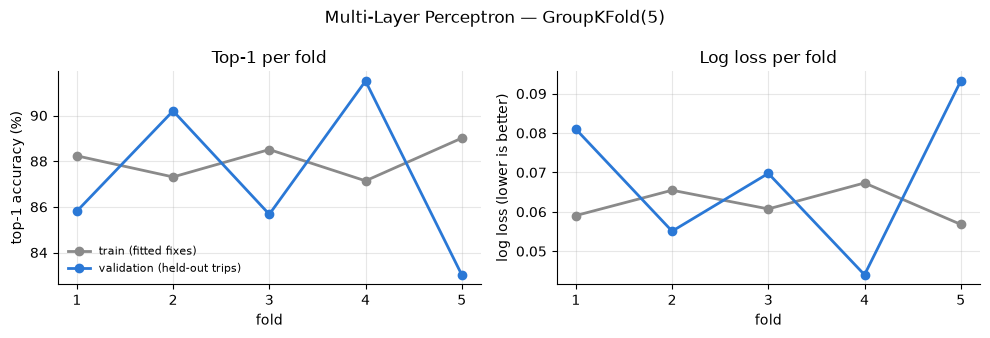

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.8884
top1_all,0.8513
macro_f1,0.7721
logloss,0.0542
precision,0.8898
recall,0.8737
f1,0.8817
continuity,0.9781
route_f1,0.9109
fit_s,170.1727


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9441,0.7395,0.9888,0.9579
1,00000007,1354,0.9770,0.9536,0.9993,0.9847
2,00000009,1049,0.8704,0.8091,0.9742,0.8831
3,00000040,2995,0.9473,0.8103,0.9950,0.9281
4,00000052,262,0.9733,0.8835,0.9885,0.9718
5,00000056,3958,0.8970,0.8287,0.9464,0.9088
6,00000065,768,0.8346,0.7047,0.9752,0.9083
7,00000076,1486,0.8681,0.6362,0.9582,0.8490
8,00000077,3911,0.7676,0.6096,0.9944,0.7944
9,00000091,874,0.8570,0.7454,0.9656,0.9227


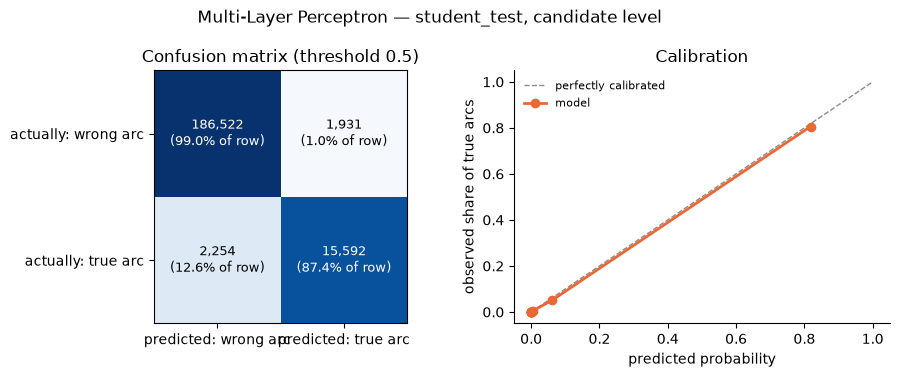

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Training and validation loss per epoch (all 5 folds)

Recorded during the CV fits above: train log loss on 100 k of the fold's training rows, validation log loss on
~10 k fixes of the fold's held-out trips. These are real histories; nothing was stopped or selected using them.

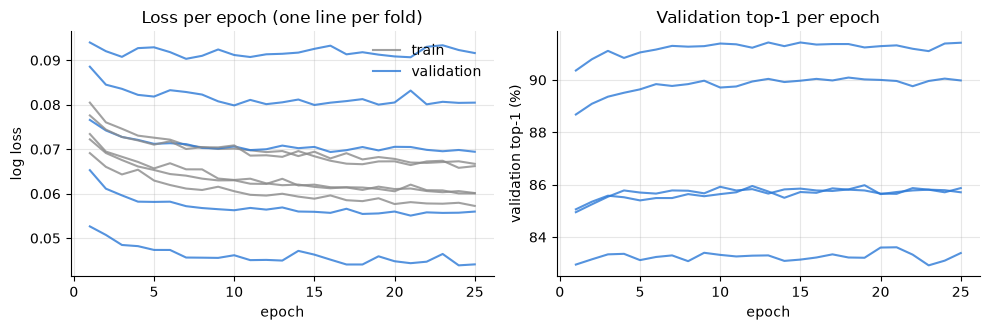

,train_logloss,val_logloss,val_top1
epoch,,,
1,0.0746,0.0754,0.8640
5,0.0675,0.0703,0.8698
10,0.0655,0.0688,0.8720
15,0.0641,0.0690,0.8722
20,0.0629,0.0685,0.8724
25,0.0621,0.0683,0.8727


In [5]:
hist = pd.concat([pd.DataFrame(m.history).assign(fold=k + 1) for k, m in enumerate(cv_models)])
hist.to_csv(OUT_DIR / NAME / "epoch_history.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, h in hist.groupby("fold"):
    ax[0].plot(h.epoch, h.train_logloss, color=GREY, lw=1.5, alpha=.8, label="train" if k == 1 else None)
    ax[0].plot(h.epoch, h.val_logloss, color=BLUE, lw=1.5, alpha=.8, label="validation" if k == 1 else None)
    ax[1].plot(h.epoch, h.val_top1 * 100, color=BLUE, lw=1.5, alpha=.8)
ax[0].set(xlabel="epoch", ylabel="log loss", title="Loss per epoch (one line per fold)"); ax[0].legend(frameon=False)
ax[1].set(xlabel="epoch", ylabel="validation top-1 (%)", title="Validation top-1 per epoch")
for a in ax: a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / NAME / "fig_history.png", dpi=150); plt.show()
hist.groupby("epoch")[["train_logloss", "val_logloss", "val_top1"]].mean().iloc[[0, 4, 9, 14, 19, 24]].round(4)

## Save results

Writes `models_out/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [6]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "mlp",
 "family": "Neural network",
 "config": {
  "hidden_layer_sizes": [
   64,
   32
  ],
  "activation": "relu",
  "alpha": 0.0001,
  "learning_rate_init": 0.001,
  "batch_size": 512,
  "epochs": 25,
  "optimizer": "adam",
  "preprocessing": "log1p+standardise, one-hot conn_prev",
  "train_frac": 0.4,
  "random_state": 42
 }
}
saved to /home/av8/Documents/ML/Hackathon/models_out/mlp
